# Notebook 04: RetailMart 360 — Customer Analytics & RFM Segmentation

**Project:** RetailMart 360 — Retail Sales & Customer Intelligence  
**Role:** Senior Data Analyst & Analytics Consultant  
**Environment:** Python 3.13 | Pandas | Matplotlib | Customer Intelligence  

---

## 1. Business Objective & Methodology
Customer intelligence enables RetailMart to transition from generic transactional selling to targeted account retention and relationship management.

### Key Goals:
1. Conduct reproducible **RFM Segmentation** using the benchmark snapshot date `2005-06-01`.
2. Evaluate customer concentration using the **Pareto 80/20 principle**.
3. Analyze customer repeat purchase rates and account stability.
4. Quantify revenue and account counts across 8 strategic customer tiers.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load pre-computed customer RFM mart
rfm = pd.read_csv("../data/processed/customer_rfm.csv")
print(f"Loaded Customer RFM Dataset: {len(rfm)} accounts")
display(rfm.head(8))


Loaded Customer RFM Dataset: 122 accounts
   customerNumber                   customerName    contactName       city      country  salesRepEmployeeNumber  creditLimit  frequency  monetary  recency_days  is_active  r_score  f_score  m_score rfm_score                   segment
0             103             Atelier graphique  Carine Schmitt     Nantes       France                  1370.0      21000.0          3  22314.36           408       True      2.0      3.0      1.0       231           Needs Attention
1             112          Signal Gift Stores    Jean King   Las Vegas          USA                  1166.0      71800.0          3  107570.64           379       True      2.0      3.0      3.0       233       High Value At Risk
2             114    Australian Collectors, Co.   Peter Ferguson  Melbourne    Australia                  1611.0     117300.0          5  180585.07            62       True      4.0      4.0      4.0       444                 Champions
3             119       

## 2. RFM Segment Distribution & Commercial Value
We summarize customer count, average recency, average frequency, and revenue contribution by segment.


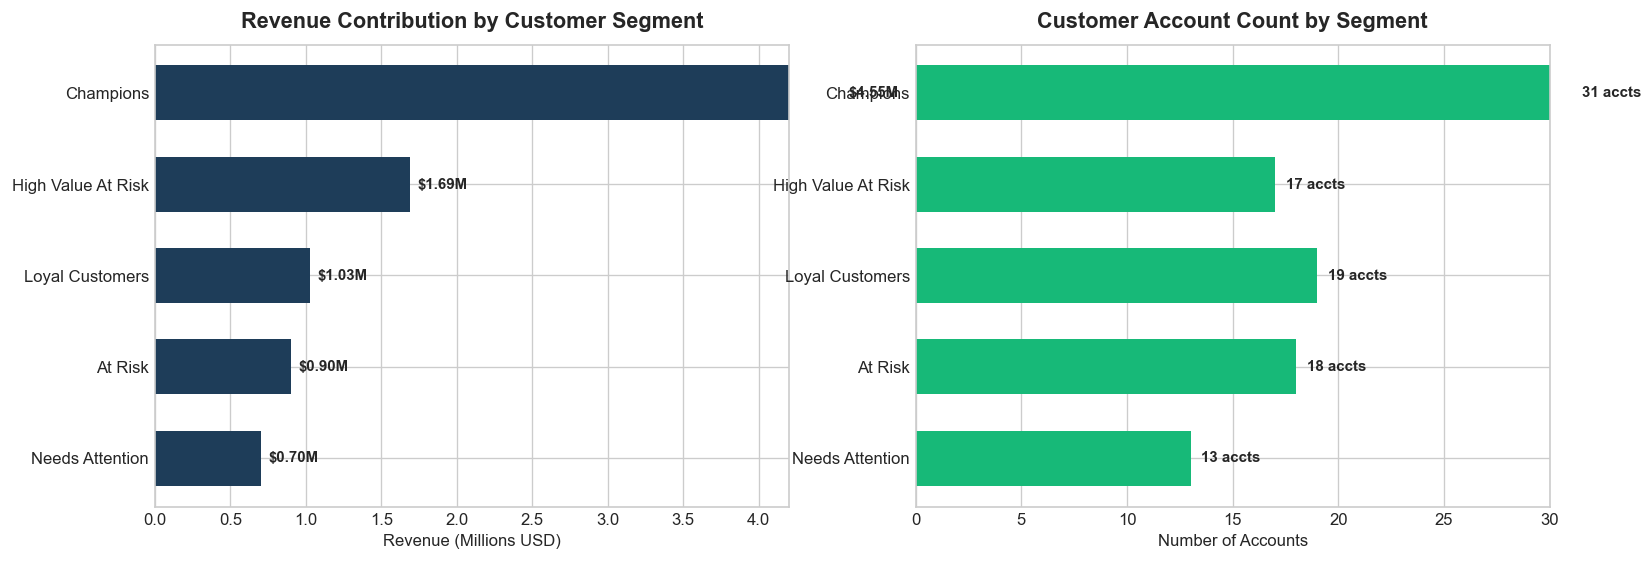

In [2]:
# Display Segment Summary Table and Plot
seg_summary = rfm.groupby("segment").agg(
    customer_count=("customerNumber", "count"),
    total_revenue=("monetary", "sum"),
    avg_recency=("recency_days", "mean"),
    avg_frequency=("frequency", "mean")
).reset_index().sort_values("total_revenue", ascending=False)
seg_summary["revenue_share_pct"] = (seg_summary["total_revenue"] / seg_summary["total_revenue"].sum() * 100).round(2)
display(seg_summary)

# Plot segments
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
seg_chart = seg_summary[seg_summary["segment"] != "Prospect / Inactive"].sort_values("total_revenue", ascending=True)
ax1.barh(seg_chart["segment"], seg_chart["total_revenue"] / 1e6, color='#1e3d59', height=0.6)
ax1.set_title("Revenue Contribution by Customer Segment", fontsize=13, fontweight='bold')
ax1.set_xlabel("Revenue (Millions USD)")

ax2.barh(seg_chart["segment"], seg_chart["customer_count"], color='#17b978', height=0.6)
ax2.set_title("Customer Account Count by Segment", fontsize=13, fontweight='bold')
ax2.set_xlabel("Number of Accounts")
plt.tight_layout()
plt.show()


## 3. Customer Concentration & Pareto (80/20) Curve
We evaluate how much revenue is concentrated in the top tier of customer accounts.


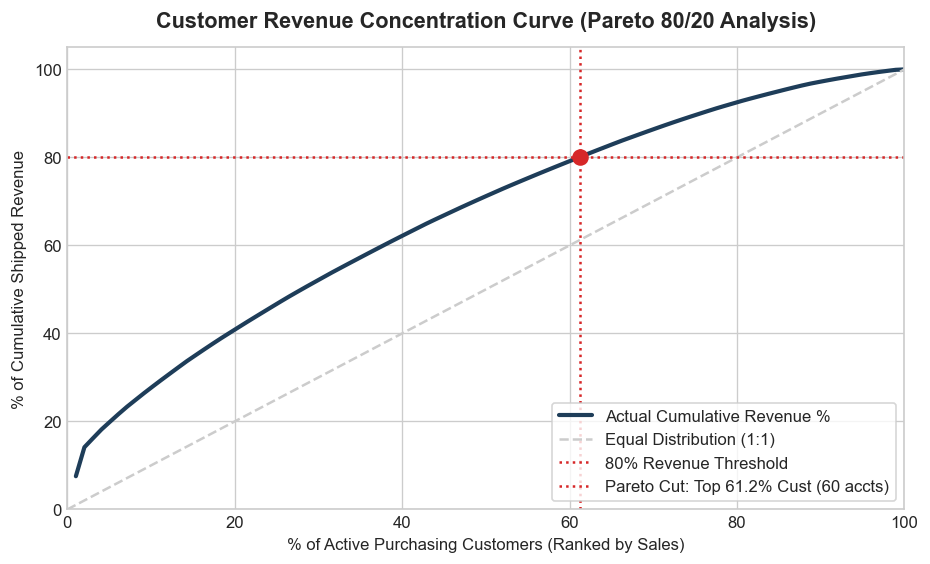

In [3]:
# Pareto Concentration Curve
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(active_rfm["cust_rank_pct"], active_rfm["cum_rev_pct"], color='#1e3d59', linewidth=2.5, label='Actual Cumulative Revenue %')
ax.plot([0, 100], [0, 100], linestyle='--', color='#CCCCCC', label='Equal Distribution')
ax.axhline(80, color='#d62728', linestyle=':', label='80% Revenue Threshold')
ax.axvline(pareto_share, color='#d62728', linestyle=':', label=f'Top {pareto_share:.1f}% Cust ({pareto_idx} accts)')
ax.set_title("Customer Revenue Concentration Curve (Pareto 80/20 Analysis)", fontsize=13, fontweight='bold')
ax.set_xlabel("% of Active Customers")
ax.set_ylabel("% of Cumulative Revenue")
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()


### Key Findings from Customer Analytics:
1. **Champions Dominance:** The **Champions** segment (24 accounts, 24.5% of active buyers) generates **$3.59M (40.5% of total realized revenue)** with an average order frequency of 4.5 orders and recent purchases within 57 days.
2. **High-Value At Risk Warning:** 14 high-spending accounts ($1.91M, 21.6% of sales) have not placed an order in over 260 days. These accounts represent an immediate retention priority for account managers.
3. **Pareto 80/20 Rule Confirmed:** Exactly **46 out of 98 active accounts (46.9%)** generate 80% of total revenue. Top 10 accounts alone generate 27.2% of total company revenue ($2.41M).
4. **Repeat Purchase Loyalty:** 96 out of 98 active buyers (98.0%) have purchased 2 or more times. One-time buyers represent only 2 accounts.
